## 1.1 Testing transforms and plotting 

level 0 nodes:
node:  [0.0-1.5e7 Hz]
energy: 1.863e-1

level 1 nodes:
node: a [0.0-7.5e6 Hz]
energy: 3.326e-1

node: d [7.5e6-1.5e7 Hz]
energy: 3.66e-5

level 2 nodes:
node: aa [0.0-3.75e6 Hz]
energy: 5.475e-1

node: ad [3.75e6-7.5e6 Hz]
energy: 3.371e-4

node: da [7.5e6-1.125e7 Hz]
energy: 2.427e-5

node: dd [1.125e7-1.5e7 Hz]
energy: 3.601e-5

level 3 nodes:
node: aaa [0.0-1.875e6 Hz]
energy: 2.667e-1

node: aad [1.875e6-3.75e6 Hz]
energy: 5.311e-1

node: ada [3.75e6-5.625e6 Hz]
energy: 1.703e-4

node: add [5.625e6-7.5e6 Hz]
energy: 3.21e-4

node: daa [7.5e6-9.375e6 Hz]
energy: 9.803e-6

node: dad [9.375e6-1.125e7 Hz]
energy: 2.556e-5

node: dda [1.125e7-1.312e7 Hz]
energy: 1.229e-5

node: ddd [1.312e7-1.5e7 Hz]
energy: 4.018e-5



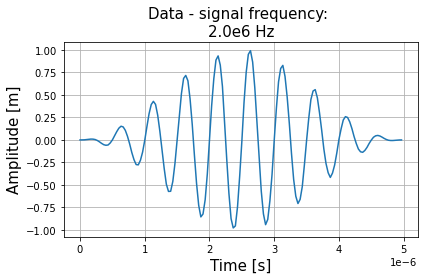

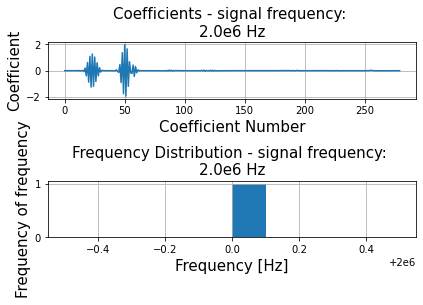

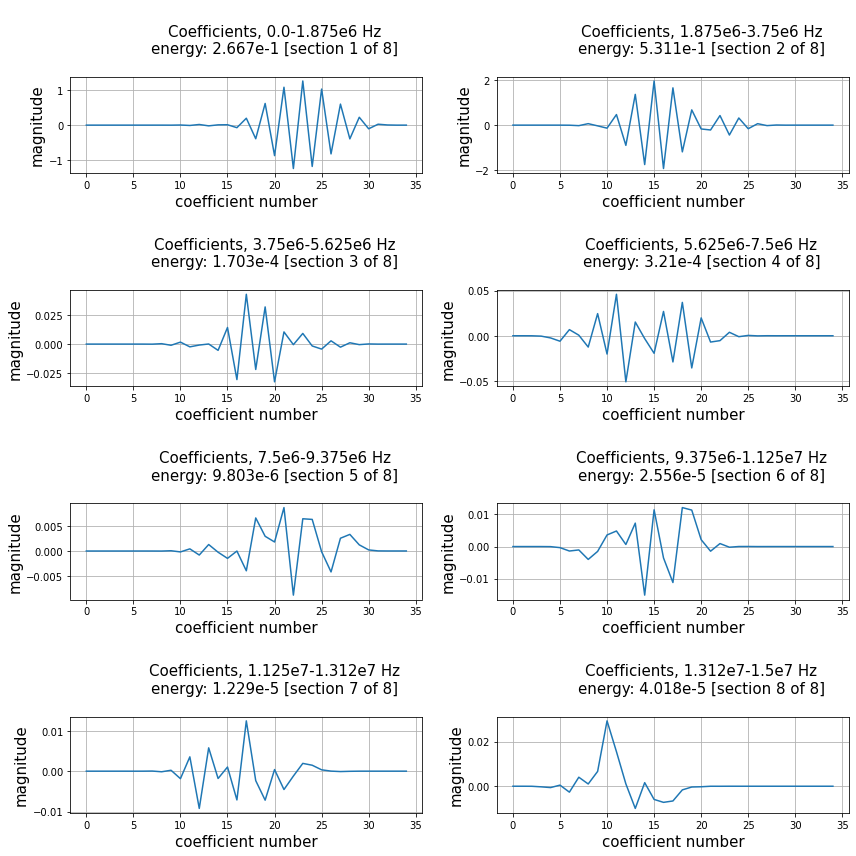

In [2]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.utils.extensions import sci_form
from wavelet_transform.test import plotting as test_plot

import matplotlib.pyplot as plt
from scipy.signal import hanning

amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6

test_frequencies = [2e6]

for frequency in test_frequencies:
    frequencies = [frequency] # create list of frequencies for synthetic data
    time_period = 1/frequency
    signal_duration = 10*time_period # duration of the signal is 10 times the test frequency
    delay = 0#2*time_period # signal starts 2 time periods late
    end = signal_duration#8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 0.01 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate, delay, end
        )

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise
    data = hanning(len(data))*data

    # transform parameters
    levels = 3
    db_order = 10
    wavelet = f'db{db_order}'

    # transform
    transform_object = wpt.dwpt(data,levels,wavelet,'constant')
    final_level_nodes = transform_object.get_level(levels)
    dwt_nodes = transform_object.dwt_results() # the dwt results can be extracted from the dwpt

    # calculate energy
    transform_object.calc_frequencies(sampling_rate)
    transform_object.show_all_energy()

    # set title
    f = sci_form(frequency)
    title = f"- signal frequency: \n{f} Hz"

    # plot everything
    plot.full_plot(
        final_level_nodes, data, t_plot, sampling_rate, 
        title, frequencies
        )

## 1.2 Testing with pywt library

length pywt:  736


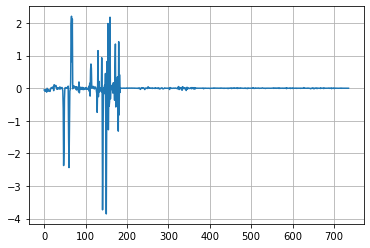

length output:  736


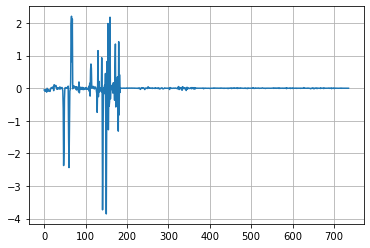

[ 1.38777878e-17 -2.77555756e-17  1.38777878e-17  0.00000000e+00
  1.38777878e-17 -2.77555756e-17 -1.38777878e-17  1.73472348e-17
  6.93889390e-18  0.00000000e+00  0.00000000e+00 -6.93889390e-18
  3.46944695e-17  0.00000000e+00 -4.16333634e-17  3.46944695e-17
  9.88792381e-17  9.02056208e-17 -1.94289029e-16 -9.10729825e-17
  1.04083409e-17 -4.85722573e-17  1.31838984e-16  1.38777878e-17
 -2.77555756e-17  1.38777878e-17  6.93889390e-18  2.08166817e-17
 -4.16333634e-17  0.00000000e+00  3.81639165e-17 -1.38777878e-17
 -3.78169718e-16 -6.38378239e-16  4.07660017e-16  1.30104261e-17
 -1.73472348e-17  1.38777878e-17 -3.46944695e-17 -5.89805982e-17
 -2.24863531e-16  6.31439345e-16  4.09557371e-16 -2.11636264e-16
  6.24500451e-17 -4.16333634e-17 -2.22044605e-16  4.44089210e-16
  4.44089210e-16  1.11022302e-16  2.94902991e-17  1.04083409e-17
 -2.42861287e-17  6.93889390e-18 -8.67361738e-18 -8.67361738e-18
 -1.04083409e-17 -8.67361738e-19  4.16333634e-17  2.22044605e-16
  0.00000000e+00 -2.22044

In [28]:
import pywt
# test result against pywt library
pywp_object = pywt.WaveletPacket(data,wavelet,maxlevel = 5)
pywt_result = test_plot.plot_pywp_test(pywp_object,levels)
my_result = test_plot.plot_test(final_level_nodes)
print(pywt_result-my_result)

## 1.3 specifying nodes to plot

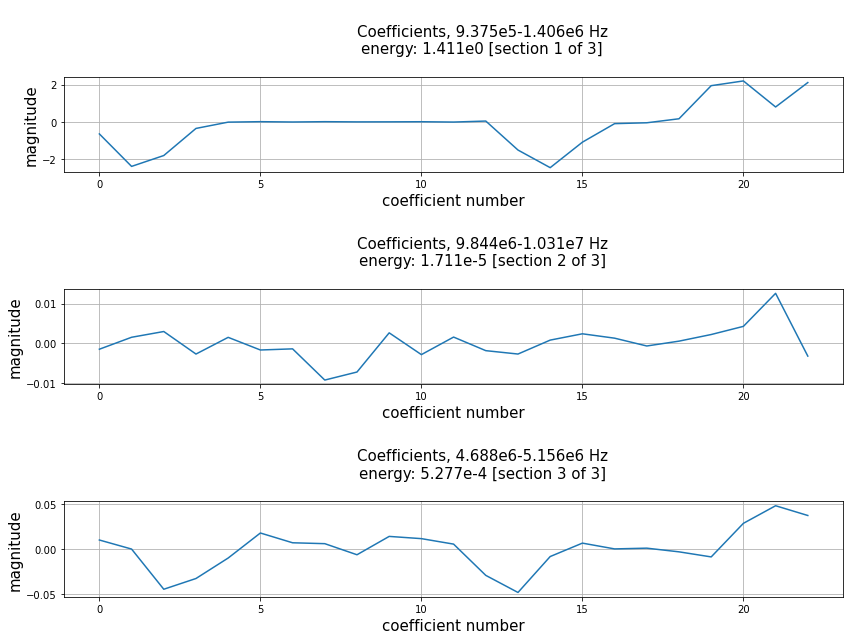

In [2]:
# find nodes with frequencies of interest
frequencies_of_interest = [1e6,1e7,0.5e7]

nodes_of_interest = transform_object.find_nodes(final_level_nodes,frequencies_of_interest)

# plot data from selected nodes
rows = int(len(nodes_of_interest))

fig,ax = plt.subplots(rows)
plot.plot_nodes(nodes_of_interest,ax,sampling_rate,rows,columns = 1)
fig.set_size_inches(12,3*rows)
fig.tight_layout()

## 2.1 Testing inverse transform

In [17]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.wpt import transform as wpt
import numpy as np
from wavelet_transform.test import synthetic_data as sd

from scipy.signal import blackmanharris
import matplotlib.pyplot as plt

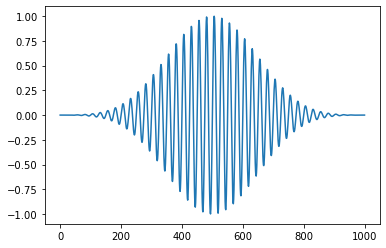

dwt inverse [-8.01504926e-19  1.50602805e-05  2.99817218e-05 ...  2.22769665e-19
  9.65617560e-20 -4.36221968e-20]
error dwt [ 8.01504926e-19  7.96210970e-19  7.82658443e-19 ... -2.50721752e-19
 -2.22769665e-19 -9.65617560e-20]
dwpt inverse [ 4.92301902e-17  1.50602805e-05  2.99817218e-05 ... -1.98964517e-04
 -2.15730063e-04 -2.30029740e-04]
length of dwpt inverse 1098
total error, packet 1.6762043613944193e-14


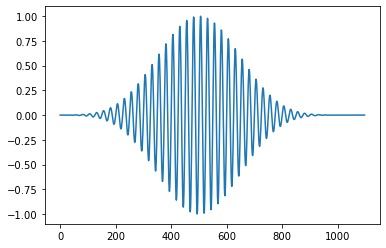

In [21]:
# transform
levels = 8
wavelet = 'db38'
sf = 50e6
freq = 2e6
amp_sin_waves = 1
frequencies = [freq]
signal_duration = 1000/sf
data, t_plot = sd.sound_wave(
    amp_sin_waves, frequencies, signal_duration, 
    sampling_rate=sf
    )
data = data*blackmanharris(len(data))
plt.plot(data)
plt.show()
transform_object = wpt.dwpt(data,levels, wavelet)

# inverse dwt
dwt_result_nodes = transform_object.dwt_results() # extract the results for the discrete wavelet transform
dwt_coeffs = transform_object.nodes2data(dwt_result_nodes) # extract the coefficients from the nodes
dwt_inverse = inv.inv_dwt(dwt_coeffs,wavelet) # inverse transform
print('dwt inverse',dwt_inverse)
print('error dwt',data-dwt_inverse[:len(data)])

# inverse dwpt
dwpt_result_nodes = transform_object.get_level(levels) # list all nodes at the final level
dwpt_coeffs = transform_object.nodes2data(dwpt_result_nodes)
dwpt_inverse = inv.inv_dwpt(dwpt_coeffs, wavelet)
print('dwpt inverse',dwpt_inverse)
print('length of dwpt inverse', len(dwpt_inverse))
print('total error, packet', sum(np.array(data)-dwpt_inverse[:len(data)]))
plt.plot(dwpt_inverse)
plt.show()

## 2.2 Testing inverse transform with synthetic data

The data is generated using the synthetic data package. Nodes are chosen for reconstruction and then the reconstructed sine wave is plotted alongside the transform results.

selecting the same nodes using different methods
keep [<wavelet_transform.wpt.transform_object.Node object at 0x00000264C97A8F10>, <wavelet_transform.wpt.transform_object.Node object at 0x00000264C954BFD0>, None, None]
leave [<wavelet_transform.wpt.transform_object.Node object at 0x00000264C97A8F10>, <wavelet_transform.wpt.transform_object.Node object at 0x00000264C954BFD0>, None, None]
min_energy [<wavelet_transform.wpt.transform_object.Node object at 0x00000264C97A8F10>, <wavelet_transform.wpt.transform_object.Node object at 0x00000264C954BFD0>, None, None]
frequencies_to_keep [<wavelet_transform.wpt.transform_object.Node object at 0x00000264C97A8F10>, <wavelet_transform.wpt.transform_object.Node object at 0x00000264C954BFD0>, None, None]


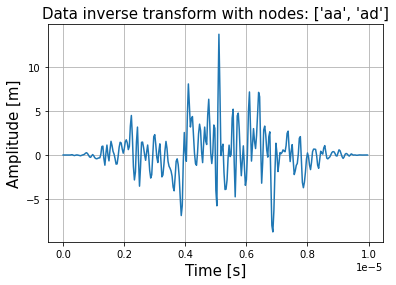

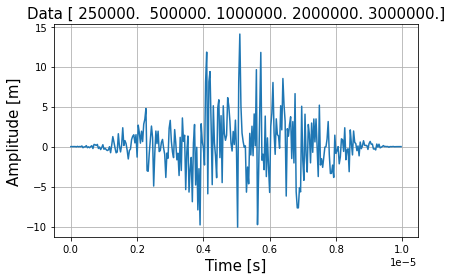

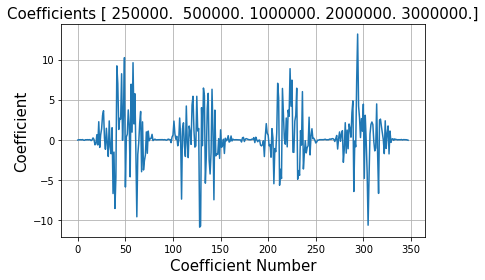

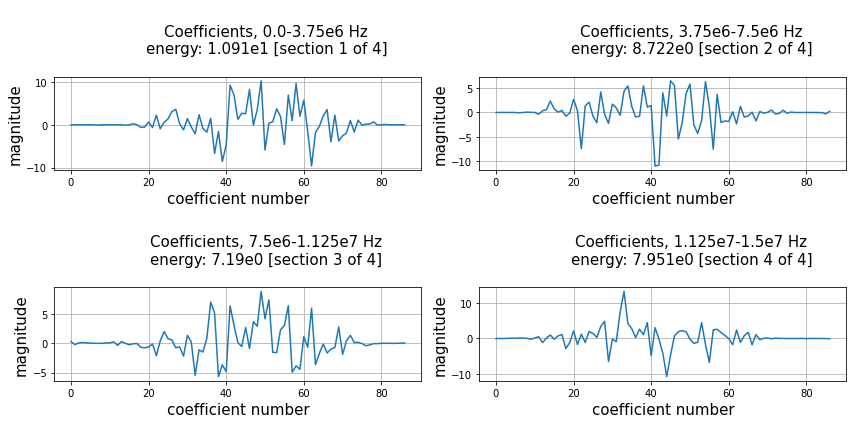

In [4]:
from numpy.random import seed

seed(seed = 1)

# set parameters for synthetic data
amp_sin_waves = 1 # amplitude of each sine wave that is added to the sound wave
sampling_rate = 30e6

test_frequencies = [1e6] # list of frequencies to test
harmonics = [1/4, 1/2, 1, 2, 3] # list of harmonics to test for each frequency

for frequency in test_frequencies:
    frequencies = frequency*np.array(harmonics)

    time_period = 1/frequency
    signal_duration = 10*time_period # signal duration is 10 times the period of the central frequency
    delay = 2*time_period # signal starts 2 time periods late
    end = 8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 5 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate, delay, end
        )

    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise
    data = hanning(len(data))*data

    # set parameters for transform
    levels = 2
    db_order = 9
    wavelet = f'db{db_order}'

    # transform
    transform_object = wpt.dwpt(data,levels,wavelet)
    final_nodes = transform_object.get_level(levels) # collect nodes from the last level
    transform_object.calc_frequencies(sampling_rate) # calculate the frequency ranges for each node

    # select nodes for inverse dwpt, each example shows a different method to select the same nodes
    print('selecting the same nodes using different methods')
    nodes_to_keep = ['aa','ad'] # keep and leave generate the same nodes
    dwpt_result_nodes = transform_object.packet_nodes_for_rec(levels,keep=nodes_to_keep)
    print('keep',dwpt_result_nodes)

    nodes_to_leave = ['da','dd'] # select nodes by specifying which to leave out
    dwpt_result_nodes = transform_object.packet_nodes_for_rec(levels,leave=nodes_to_leave)
    print('leave',dwpt_result_nodes)

    dwpt_result_nodes = transform_object.packet_nodes_for_rec(levels,min_energy=8) # specify min. energy
    print('min_energy',dwpt_result_nodes) 

    frequencies_to_keep = [0,5e6] # specify frequencies to keep
    dwpt_result_nodes = transform_object.packet_nodes_for_rec(levels,keep=frequencies_to_keep)
    print('frequencies_to_keep',dwpt_result_nodes)

    # convert list of nodes to list of arrays containing data from each node, then transform
    kept_coefficients = transform_object.nodes2data(dwpt_result_nodes) # call nodes2data before inverse
    inverse = inv.inv_dwpt(kept_coefficients,wavelet)
    inverse = inverse[:len(data)]

    # plot inverse transform
    title = f'inverse transform with nodes: \n{nodes_to_keep}'
    fig,ax = plt.subplots()
    plot.plot_wave(inverse,t_plot,ax,title)
    plt.show()

    # plot initial wave and transform coefficients
    plot.full_plot(final_nodes,data,t_plot,sampling_rate,frequencies)